downloading trial #92
downloading AF_20250817_112358.edf
downloading AF_20250817_112358.lay
downloading AF_20250817_112358.stat
javascript v1.1
time offset is -300
Trials/92/
trialData.txt
AF_20250817_112358.lay
AF_20250817_112358.stat
AF_20250817_112358.edf
edf file is AF_20250817_112358.edf
Trials/92/AF_20250817_112358.edf
recognitionPresses.txt
trial.json
json file is trial.json
Trials/92/trial.json
26
EEG start time: 2025-08-17 11:23:58
trial timestamp: 2025-08-17 11:26:00
time difference by trial start time: 0:02:02
fs: 250.000000
start time of trial, before the calibration flashes:  0:02:32.630000
start time: 152.63
-500.000000 - 5000.000000
152130.000000 - 157630.000000
startTime is 152.630000
154715.0


/var/folders/5t/m891cqsd1hng2vz4sdkpjfjc0000gn/T/ipykernel_11951/3084802964.py:397: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  bigplot.show()


before: -75.000000, after: 75.000000, length: 150.000000


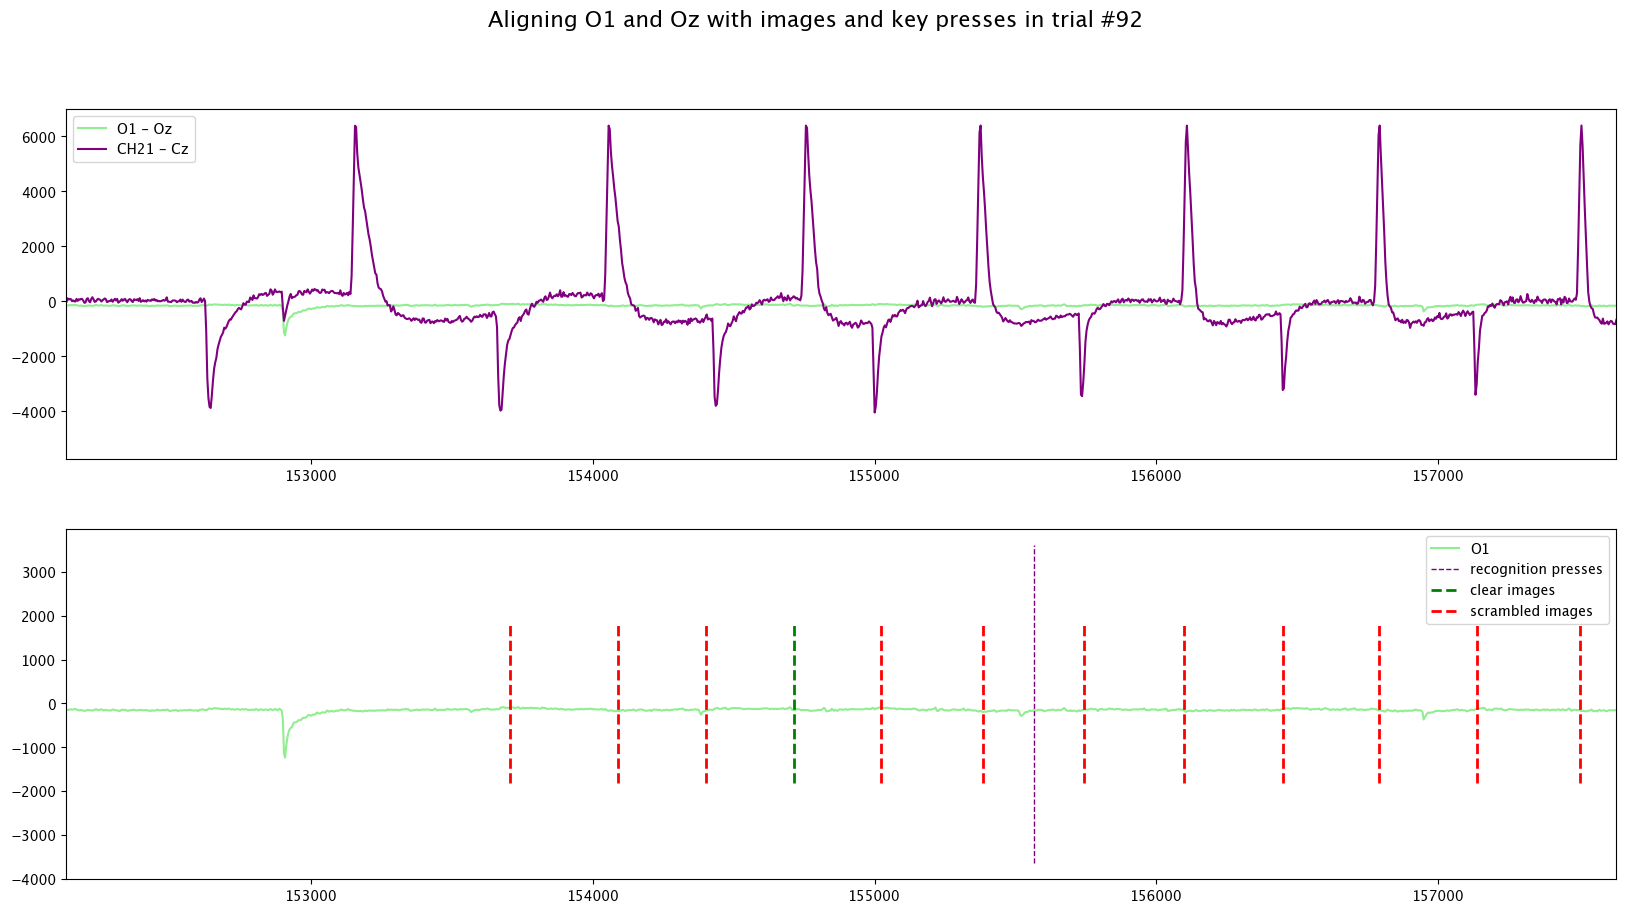

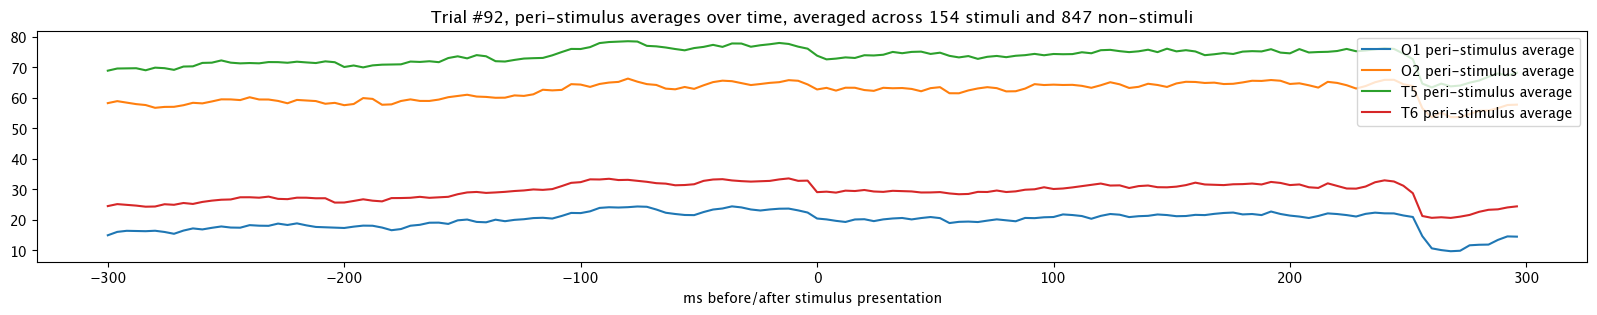

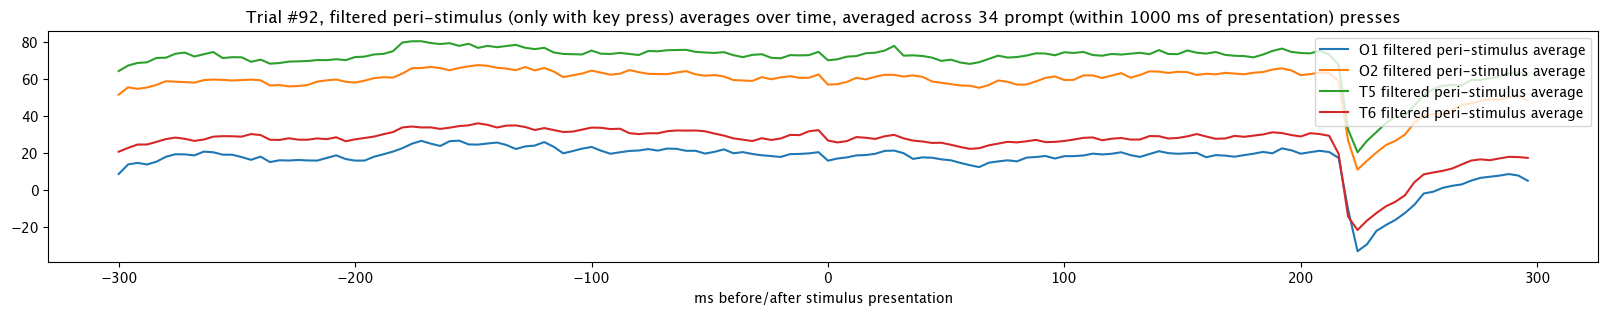

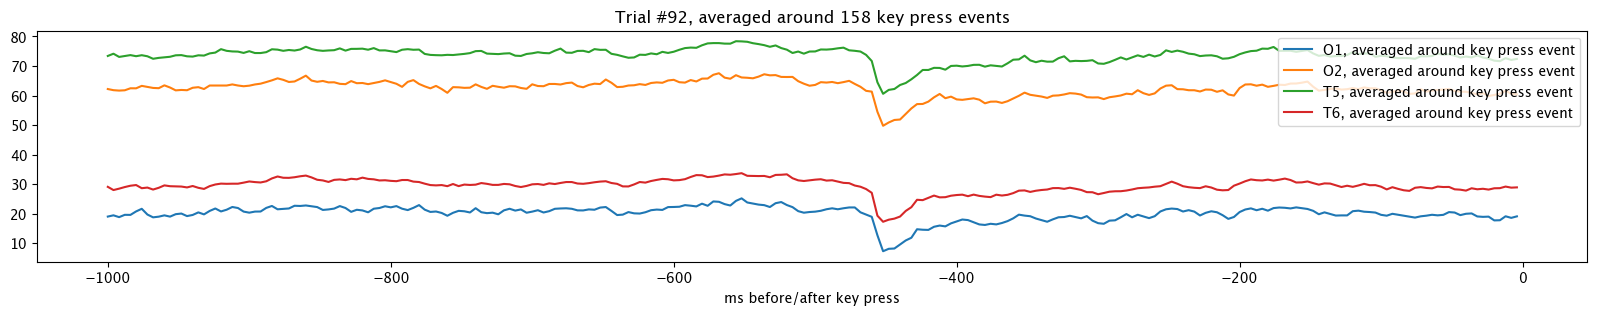

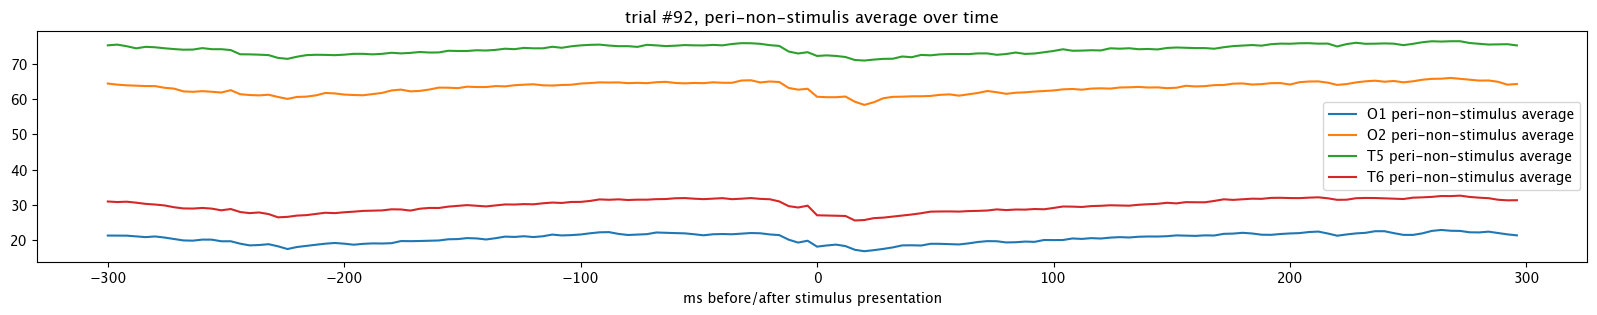

In [171]:
import pyedflib
from pyedflib import highlevel
from scipy import *
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
import sys
import os
import traceback
import scipy
from datetime import datetime
import pprint
from scipy.io import savemat, loadmat
from scipy import fftpack, linalg
import json
import csv
import urllib.request

verbose=False
fs=4
signals=[]
notchB=None
notchA=None

def create_fir_filter(num_taps, cutoff_frequency, sampling_rate):
    # Normalized cutoff frequency
    normalized_cutoff = 2 * cutoff_frequency / sampling_rate

    # Create an array of tap indices
    indices = np.arange(-num_taps // 2, num_taps // 2 + 1)

    # Calculate the sinc filter
    sinc_filter = np.sinc(normalized_cutoff * indices)

    # Apply a window function (Hann window)
    window = np.hanning(len(sinc_filter))
    fir_filter = sinc_filter * window
    return fir_filter

#this function adds and averages multiple occurrences, from 'beforeOffset' to 'afterOffset' where a signal occurs, and returns a time series with that average
#<beforeOffset> is in ms before the stimulus, <afterOffset> is in ms after the stimulus
#<stimuliList> is a list of times, in ms, that occur in <signal>.  
#the elements in signal and average have a sample frequency fs, in samples per second
def periStimulusAverage(signalName, stimuliList, beforeOffset, afterOffset):
    beforeOffset=int(-beforeOffset/(1000/fs))    
    afterOffset=int(afterOffset/(1000/fs))
    average=np.zeros(afterOffset-beforeOffset)
    com="Cz"
    O1SignalNotch=signals[signal_labels.index(signalName)]
    common=signals[signal_labels.index(com)]
    signalNotch=scipy.signal.filtfilt(notchB, notchA, O1SignalNotch)
    commonNotch=scipy.signal.filtfilt(notchB, notchA, common)
    notchDiff=signalNotch-commonNotch

    stimuli=0
    for value in stimuliList:
        stimuli+=1
        for i in range(beforeOffset, afterOffset):
                average[i]= average[i]*(stimuli-1)/stimuli + notchDiff[int(value/(1000/fs))+i]/stimuli
    return average, signalNotch
    


def readEDF(datafileDirectory,trialNumber, channel=None, hardCodedStartTime="", trimStart=0, trimEnd=5000):
    global fs, signals, signal_labels, notchB, notchA
    rootUrl="https://eegdata.artiswrong.com"
    print("downloading trial #%s" % trialNumber)
    if not os.path.isdir("%s/%s" % (datafileDirectory, trialNumber)):
        os.mkdir("%s/%s" % (datafileDirectory, trialNumber))
    trialJson=None
    
    urllib.request.urlretrieve("%s/trialData/%s" % (rootUrl, trialNumber), "%s/%s/trial.json" % (datafileDirectory, trialNumber))
    with open("%s/%s/trial.json" % (datafileDirectory, trialNumber)) as f:
        trialJson = json.load(f)
        edfField=trialJson["fields"]["edfFile"]
        layField=trialJson["fields"]["layFile"]
        statField=trialJson["fields"]["statFile"]
        
        edfFile=edfField.split('/')[1]
        print("downloading %s" % edfFile)
        urllib.request.urlretrieve("%s/media/%s" % (rootUrl, edfField), "%s/%s/%s" % (datafileDirectory, trialNumber, edfFile))
        layFile=layField.split('/')[1]
        print("downloading %s" % layFile)
        urllib.request.urlretrieve("%s/media/%s" % (rootUrl, layField), "%s/%s/%s" % (datafileDirectory, trialNumber, layFile))
        statFile=statField.split('/')[1]
        print("downloading %s" % statFile)
        urllib.request.urlretrieve("%s/media/%s" % (rootUrl, statField), "%s/%s/%s" % (datafileDirectory, trialNumber, statFile))
    
    trialTimestamp=trialJson["fields"]['trialTimestamp']
    timeOffset=0
    if trialJson["fields"]["javascriptVersion"]=="1.1":
        print("javascript v1.1")
        timeOffset=-300
        #timeOffset=-int((int(trialJson["fields"]["calibrationPeriod"])*float(trialJson["fields"]["calibrationFlashes"])))#+int(trialJson["fields"]["delayBetweenImages"])
        print("time offset is %d" % timeOffset)
    try:
        datafileDirectory="%s%s/" % (datafileDirectory, trialNumber)
        print(datafileDirectory)
        
        for root, dirs, files in os.walk(datafileDirectory):
            for file in files:
                print(file)
                if file.endswith(".edf"):
                    print("edf file is %s" % file)
                    filename=os.path.join(datafileDirectory, file)
                    print(filename)
                if file.endswith(".json"):
                    
                    print("json file is %s" % file)
                    jsonFilename=os.path.join(datafileDirectory, file)
                    print(jsonFilename)

       # layFileName = fileName[:fileName.index(".edf")] + ".lay"
        dataFileName = datafileDirectory + filename    
        signals, signal_headers, header = highlevel.read_edf(filename)
        f = pyedflib.EdfReader(filename)
        signal_labels = f.getSignalLabels()
        numChannels = f.signals_in_file
        
        f.close()
        
        recognitionPresses= json.loads(trialJson["fields"]["recognitionPresses"])
        trialData=json.loads(trialJson["fields"]["trialData"])
        if verbose:
            #print("trial data:")
            #pprint.pprint(trialData)
            #print("recognition presses:")
            #pprint.pprint(recognitionPresses)
            print("header")
            pprint.pprint(header)
            print("signal header")
            pprint.pprint(signal_headers)
        n = len(signals)
        print(n)
        
        eegStartTime=header["startdate"]
        print("EEG start time: %s" % eegStartTime)            
        trialTimestamp=datetime.strptime(trialJson["fields"]['trialTimestamp'], "%m/%d/%Y %H:%M")  
        print("trial timestamp: %s" % trialTimestamp)
        print("time difference by trial start time: %s" % (trialTimestamp-eegStartTime))
        if channel is None:            
            opticalTrigger1='CH21'  #'EKG1'
            opticalTrigger2='Cz'  #'EKG2'
            #opticalTrigger1='EKG1'  #'EKG1'
            #opticalTrigger2='EKG2'  #'EKG2'

            ekg1=signals[signal_labels.index(opticalTrigger1)]
            ekg2=signals[signal_labels.index(opticalTrigger2)]
            diff=ekg1-ekg2
            
                  #notch filter
            fs = signal_headers[0]["sample_frequency"]  # Sample frequency (Hz) (250hz by default)
            print("fs: %f" % fs)
            f0 = 60.0  # Frequency to be removed from signal (Hz)
            Q = 30.0  # Quality factor
            # Design notch filter
            notchB, notchA = signal.iirnotch(f0, Q, fs)
            notch=scipy.signal.filtfilt(notchB, notchA, diff)
            
            #trying a low-pass filter
            fs = signal_headers[0]["sample_frequency"]  # Sample frequency (Hz) (250hz by default)
            bpB, bpA = signal.butter(4, [.04, .12], 'bandpass') #, analog=True)
            
            
            #bandpass=scipy.signal.filtfilt(bpB, bpA, notch)
            bandpass=diff
            
            # Detect rising zero-crossings
            risingZeroCrossings = np.where((bandpass[:-1] < 0) & (bandpass[1:] >= 0))[0]
            differences=[]
            for index in range(1,len(risingZeroCrossings)):
                differences.append(risingZeroCrossings[index]-risingZeroCrossings[index-1])
                
            # Detect falling zero-crossings -- remember that these are sample indices and not time values
            allZeroCrossings = np.where(( (bandpass[:-1] > 0) & (bandpass[1:] <= 0)) | (bandpass[:-1] < 0) & (bandpass[1:] >= 0)) [0]                

            # Sliding window parameters
            window_size = 10  # samples
            step_size = 10     # step between windows
            num_windows = (len(bandpass) - window_size) // step_size + 1

            # Compute peak-to-peak in each window
            ptp_values = np.array([
                np.ptp(bandpass[i:i+window_size])
                for i in range(0, len(bandpass) - window_size + 1, step_size)
            ])

            # Corresponding time points (center of each window)
            times = (1000/fs)*np.array([
                i + window_size // 2
                for i in range(0, len(bandpass) - window_size + 1, step_size)
             ])
            
            riseTime=0
            threshhold=2000
            rti=0
            
            if hardCodedStartTime==False:
                for index, value in enumerate(ptp_values):
                    if value>threshhold:
                            #1000 for trial 67
                            if times[index]>1000:  #this is a hardcoded magic number for trial #67 -- there was a spike around 700 in this dataset, probably from a bit of white screen before we started the trial
                                riseTime=times[index]
                                rti=index
                                print("rise time is: %d" % riseTime)
                                print("rise time index is: %d" % rti)
                                break
            
                cycleCount=0
                numCycles=2
                endInitiationCycles=0
                for index, value in enumerate(risingZeroCrossings):
                    if value>riseTime:
                        cycleCount+=1
                        if cycleCount==numCycles:
                            endInitiationCycles=value
                            break
                 
                startTime=0
                startSample=0
                for index, value in enumerate(allZeroCrossings):
                    if value>endInitiationCycles:
                        startSample=value
                        startTime=value * 1000/fs # the data is in samples, and to convert to a time value in milliseconds, we gotta divide by the sample frequency
                        break
            else:
                edfStartTime=datetime.strptime(trialJson["fields"]['EDFStartTime'], "%H:%M:%S.%f")
                edfStartTime=datetime.combine(eegStartTime.date(), edfStartTime.time())
                print("start time of trial, before the calibration flashes:  %s" % (edfStartTime-eegStartTime))
                startTime=(edfStartTime-eegStartTime).total_seconds()
                print("start time: %s" % startTime)
                startSample=int(startTime*fs/1000)
                print("%f - %f" % (trimStart, trimEnd))
                trimStart+=startTime*1000
                trimEnd+=startTime*1000
                print("%f - %f" % (trimStart, trimEnd))
            time = np.arange(len(diff)) * 1000/fs
            
            print("startTime is %f" % startTime)
            cleanDict={}
            scrambledImages={}
            clearImages={}
            filteredImages={}
            promptDelay=1000 
            for key, value in trialData['data'].items():
                if key.isdigit():
                    cleanDict[int(key)]=value
                    values=value.split(",")
                    if values[2]=='false':
                        t=int(round(float(values[0])))+float(startTime*1000)+timeOffset
                        clearImages[t]=values[1]
                        filtered=False
                        for val in recognitionPresses:
                            if val>t and val<t + promptDelay:
                                if not filtered:
                                    filteredImages[val]=values[1]
                                filtered=True
                    else:
                        scrambledImages[int(round(float(values[0])))+float(startTime*1000)+timeOffset]=values[1]
                else:
                    cleanDict[key]=value
            for index, value in enumerate(recognitionPresses):
                recognitionPresses[index]=value + startTime*1000 + timeOffset   #offset the recognition press time (time =0 is the first image) to line up with the start time on the EEG
            print(list(clearImages.keys())[0])
            #fig, axs = plt.subplots(6, 1, figsize=(6,8))
            #fig.suptitle("Aligning image display data with trial data", fontsize=16)
            #axs[0].plot(time, diff , color='purple' )
            #axs[1].plot(time, notch, color='pink')
            #axs[2].plot(time, bandpass, color='green', label='notch and bandpassed for screen signal')
            #axs[2].plot(startTime, bandpass[startSample], 'o', color='red')
            #axs[3].plot(times, ptp_values, color='blue',  label='Peak to Peak amplitude of EKG difference')
            #axs[3].plot( riseTime, ptp_values[rti], 'o', color='red')
            #axs[4].plot( allZeroCrossings, bandpass[allZeroCrossings], 'o', color='gray')
            #axs[4].plot((1000/fs)*risingZeroCrossings, bandpass[risingZeroCrossings], 'o', color='red', label='Rising edges')
            
            

            beforeOffset=300 #ms
        
            afterOffset=300 #ms
            O1psa, O1SignalNotch=periStimulusAverage("O1", clearImages.keys(), beforeOffset, afterOffset)
            O2psa, O2SignalNotch=periStimulusAverage("O2", clearImages.keys(), beforeOffset, afterOffset)
            T5psa, T5SignalNotch=periStimulusAverage("T5", clearImages.keys(), beforeOffset, afterOffset)
            T6psa, T6SignalNotch=periStimulusAverage("T6", clearImages.keys(), beforeOffset, afterOffset)

            O1fpsa, tmp=periStimulusAverage("O1", filteredImages.keys(), beforeOffset, afterOffset)
            O2fpsa, tmp=periStimulusAverage("O2", filteredImages.keys(), beforeOffset, afterOffset)
            T5fpsa, tmp=periStimulusAverage("T5", filteredImages.keys(), beforeOffset, afterOffset)
            T6fpsa, tmp=periStimulusAverage("T6", filteredImages.keys(), beforeOffset, afterOffset)

            O1kppsa, tmp=periStimulusAverage("O1", recognitionPresses, promptDelay, 0)
            O2kppsa, tmp=periStimulusAverage("O2", recognitionPresses, promptDelay, 0)
            T5kppsa, tmp=periStimulusAverage("T5", recognitionPresses, promptDelay, 0)
            T6kppsa, tmp=periStimulusAverage("T6", recognitionPresses, promptDelay, 0)
            
            
            O1pnsa, tmp=periStimulusAverage("O1", scrambledImages.keys(), beforeOffset, afterOffset)
            O2pnsa, tmp=periStimulusAverage("O2", scrambledImages.keys(), beforeOffset, afterOffset)
            T5pnsa, tmp=periStimulusAverage("T5", scrambledImages.keys(), beforeOffset, afterOffset)
            T6pnsa, tmp=periStimulusAverage("T6", scrambledImages.keys(), beforeOffset, afterOffset)
            
            '''
            filteredPeriStimulusAverage=np.zeros(afterOffset-beforeOffset)
            filteredImages=0
            stimuli=0
            notchDiff=signalNotch-commonNotch
            for value in clearImages.keys():
                stimuli+=1
                clearImageWithPress=False
                for val in recognitionPresses:
                    if val-value>0 and val-value<500:
                        print("%d - %d" % (val, value))
                        clearImageWithPress=True
                if clearImageWithPress:
                    filteredImages+=1
                    for i in range(beforeOffset, afterOffset):
                        filteredPeriStimulusAverage[i]=filteredPeriStimulusAverage[i]*(filteredImages-1)/filteredImages + notchDiff[int(value/(1000/fs))+i]/filteredImages

                for i in range(beforeOffset, afterOffset):
                    periStimulusAverage[i]= periStimulusAverage[i]*(stimuli-1)/stimuli + notchDiff[int(value/(1000/fs))+i]/stimuli
                                                     

            periNonStimulusAverage=np.zeros(afterOffset-beforeOffset)
            notchDiff=signalNotch-commonNotch
            for value in scrambledImages.keys():
                for i in range(beforeOffset, afterOffset):
                    periNonStimulusAverage[i]+=notchDiff[int(value/(1000/fs))+i]/len(scrambledImages.keys())
            '''            
                        
            #axs[5].plot(time, O1SignalNotch, color="lightGreen", label="O1 notch filter")
            #axs[5].plot(time, O2SignalNotch, color="lightBlue", label="O2 notch filter")
            #axs[5].plot(time, T5SignalNotch, color="red", label="T5 notch filter")
            #axs[5].plot(time, T6SignalNotch, color="lightYellow", label="T6 notch filter")
            #axs[5].vlines(x=recognitionPresses, ymin=min(O1SignalNotch), ymax=max(O1SignalNotch), color='purple', linestyle="--", linewidth=1, label="recognition presses")
            #axs[5].vlines(x=list(clearImages.keys()), ymin=min(O1SignalNotch), ymax=max(O1SignalNotch), color='green', linestyle="--", linewidth=1, label="clear images")
            #axs[5].vlines(x=list(scrambledImages.keys()), ymin=min(O1SignalNotch), ymax=max(O1SignalNotch), color='red', linestyle="--", linewidth=1, label="scrambled images")
            
            
            '''
            # Transpose the lists so that each list becomes a column
            columns = [time, signalNotch, commonNotch, signalNotch-commonNotch, recognitionPresses, list(clearImages.keys()), list(scrambledImages.keys())]
            # Find the longest list
            max_len = max(len(col) for col in columns)

            padded_columns = [
                list(col) + [''] * max(0, max_len - len(col))
                for col in columns
                ]

            rows = zip(*padded_columns)  # Transpose using zip
            # Write to CSV
            with open('Trial %d analysis.csv' % trialNumber, 'w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(["time",sig, com, "%s-%s" % (sig, com), "recognition presses", "clear images", "scrambled images"])
                writer.writerows(rows)
    
            '''
    
            
            '''
            #plt.legend()
            plt.grid(True)
            plt.subplots_adjust(
                left=0.1,   # space from left edge of the figure
                right=0.9,  # space from right edge
                top=0.9,    # space from top
                bottom=0.1, # space from bottom
                wspace=0.5, # width (horizontal) space between subplots
                hspace=0.5  # height (vertical) space between subplots
            )
            for ax in axs:
                ax.legend()
                ax.set_xlim(2000, 5000)          
             
            print(len(ekg1))
            plt.show()
            '''
            
            sig="O1"
            com="Oz"
            
            bigplot, axes=plt.subplots(2,1,figsize=(20,10))
            bigplot.suptitle("Aligning %s and %s with images and key presses in trial #%s" % (sig, com, trialNumber), fontsize=16)

            axes[0].plot(time, O1SignalNotch, color="lightGreen", label="%s - %s" % (sig, com))
            axes[0].plot(time, diff, color="purple", label="CH21 - Cz")
#            axes[0].plot(time, O2Notch, color="orange", label="O2")
            axes[1].plot(time, O1SignalNotch, color="lightGreen", label=sig)
            axes[1].vlines(x=recognitionPresses, ymin=min(O1SignalNotch), ymax=max(O1SignalNotch), color='purple', linestyle="--", linewidth=1, label="recognition presses")
            axes[1].vlines(x=list(clearImages.keys()), ymin=min(O1SignalNotch)/2, ymax=max(O1SignalNotch)/2, color='green', linestyle="--", linewidth=2, label="clear images")
            axes[1].vlines(x=list(scrambledImages.keys()), ymin=min(O1SignalNotch)/2, ymax=max(O1SignalNotch)/2, color='red', linestyle="--", linewidth=2, label="scrambled images")            
            axes[0].legend()
            axes[1].legend()
            axes[0].set_xlim(trimStart, trimEnd)
            axes[1].set_xlim(trimStart, trimEnd)            
            bigplot.show()
            
            periStimulusTime = np.arange(-beforeOffset, afterOffset, 1000/fs)
            print("before: %f, after: %f, length: %f" % (-beforeOffset/(1000/fs), afterOffset/(1000/fs), len(periStimulusTime)))
            plt.figure(figsize=(20, 3))
            plt.title("Trial #%d, peri-stimulus averages over time, averaged across %d stimuli and %d non-stimuli" % (trialNumber, len(clearImages.keys()), len(scrambledImages.keys())))
            plt.plot(periStimulusTime,O1psa, label="O1 peri-stimulus average")
            plt.plot(periStimulusTime,O2psa, label="O2 peri-stimulus average")
            plt.plot(periStimulusTime,T5psa, label="T5 peri-stimulus average")
            plt.plot(periStimulusTime,T6psa, label="T6 peri-stimulus average")
            plt.xlabel("ms before/after stimulus presentation")            
#            plt.plot(periStimulusTime,filteredPeriStimulusAverage, label="filtered peri-stimulus average")
            plt.legend(loc="upper right")
            plt.show()

            plt.figure(figsize=(20, 3))
            plt.title("Trial #%d, filtered peri-stimulus (only with key press) averages over time, averaged across %d prompt (within %d ms of presentation) presses" % (trialNumber, len(filteredImages.keys()), promptDelay))
            plt.plot(periStimulusTime,O1fpsa, label="O1 filtered peri-stimulus average")
            plt.plot(periStimulusTime,O2fpsa, label="O2 filtered peri-stimulus average")
            plt.plot(periStimulusTime,T5fpsa, label="T5 filtered peri-stimulus average")
            plt.plot(periStimulusTime,T6fpsa, label="T6 filtered peri-stimulus average")
            plt.xlabel("ms before/after stimulus presentation")            
#            plt.plot(periStimulusTime,filteredPeriStimulusAverage, label="filtered peri-stimulus average")
            plt.legend(loc="upper right")
            plt.show()

            kpStimulusTime = np.arange(-promptDelay, 0, 1000/fs)
            plt.figure(figsize=(20, 3))
            plt.title("Trial #%d, averaged around %d key press events" % (trialNumber, len(recognitionPresses)))
            plt.plot(kpStimulusTime,O1kppsa, label="O1, averaged around key press event")
            plt.plot(kpStimulusTime,O2kppsa, label="O2, averaged around key press event")
            plt.plot(kpStimulusTime,T5kppsa, label="T5, averaged around key press event")
            plt.plot(kpStimulusTime,T6kppsa, label="T6, averaged around key press event")
            plt.xlabel("ms before/after key press")            
#            plt.plot(periStimulusTime,filteredPeriStimulusAverage, label="filtered peri-stimulus average")
            plt.legend(loc="upper right")
            plt.show()
        
        
            plt.figure(figsize=(20, 3))
            plt.title("trial #%d, peri-non-stimulis average over time" % trialNumber)
            plt.plot(periStimulusTime,O1pnsa,  label="O1 peri-non-stimulus average")
            plt.plot(periStimulusTime,O2pnsa,  label="O2 peri-non-stimulus average")
            plt.plot(periStimulusTime,T5pnsa,  label="T5 peri-non-stimulus average")
            plt.plot(periStimulusTime,T6pnsa,  label="T6 peri-non-stimulus average")
            plt.xlabel("ms before/after stimulus presentation")
            plt.legend()
            plt.show()
        else:
            print(channel)
            
            ax.plot(signals[signal_labels.index(channel)] , color='purple' )
            plt.show()
            
            rfig, raxs=plt.subplots(1, 1, figsize=(6,8))
            rfig.suptitle("user recognition presses", fontsize=16)
            raxs[0].plot()

         #        print(f.readSignal)
         

    except:
        traceback.print_exc(file=sys.stdout)      
datafileDirectory = "Trials/"
readEDF(datafileDirectory,trialNumber=92, hardCodedStartTime=True, trimStart=-500, trimEnd=5000)


# 